![alt text](image.png)</br>
![alt text](image-2.png)

<h1 style="font-family: 'Times New Roman', Times, serif;">
    Introduction
</h1>

<div style="font-family: 'Times New Roman', Times, serif; line-height: 1.6; ">
    The Gen Guardian project comes from the vision of creating a comprehensive parenting support app designed to foster emotional regulation and child development grounded in the Finnish education model and Montessori principles. The inspiration for the app lies in a parent-first model of regulation, which posits that a caregiver’s internal emotional state is the primary catalyst for a healthy home environment. A parent cannot effectively co-regulate a child while they themselves are in a state of emotional flooding or crisis especially if they did not grow up with a good parent to model from. While the full Gen Guardian application will eventually integrate Finnish pedagogical concepts and the emphasis on the child’s holistic well-being, the work presented here represents the essential technical foundation for such a system. By implementing a high-precision classification engine to identify parental emotional states this project establishes the logic required for future development. Utilizing a refined version of the dair-ai/emotion dataset, the following analysis compares a Keyword Heuristic Baseline ~44.08% accuracy against advanced models, including a Linear SVM ~92.17% accuracy and a Tuned Random Forest, to prove the feasibility of using machine learning as a reliable first step in the Gen Guardian development roadmap.
</div>


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
 Setup and Imports
</div>

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from sklearn.pipeline import Pipeline

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")

<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
 Import dataset and extract emotion labels
 </div>

In [24]:
from datasets import load_dataset

dataset = load_dataset("dair-ai/emotion")
df = dataset['train'].to_pandas()

# Check the label column directly
print("Label values:", df['label'].unique())
print("\nLabel distribution:")
print(df['label'].value_counts().sort_index())

# Check the dataset card for the official mapping
print("\nDataset info:")
print(dataset['train'].features)


Label values: [0 3 2 5 4 1]

Label distribution:
label
0    4666
1    5362
2    1304
3    2159
4    1937
5     572
Name: count, dtype: int64

Dataset info:
{'text': Value('string'), 'label': ClassLabel(names=['sadness', 'joy', 'love', 'anger', 'fear', 'surprise'])}


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
Show Mapping
</div>

In [25]:
# emotion mapping (verified from dataset)
emotion_map = {
    0: 'sadness',
    1: 'joy',
    2: 'love',
    3: 'anger',
    4: 'fear',
    5: 'surprise'
}

df['emotion_name'] = df['label'].map(emotion_map)

print("emotion mapping applied")
print("\nOriginal emotion distribution:")
print(df['emotion_name'].value_counts())

emotion mapping applied

Original emotion distribution:
emotion_name
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64


<div style="font-family: 'Times New Roman', Times, serif; font-size: 24px;">
Consolidation for Gen Guardian
 </div>

In [26]:
# Consolidate into 6 Gen Guardian categories
consolidation_map = {
    'anger': 'anger/frustration',
    'fear': 'exhaustion/overwhelm',  # Fear → overwhelm
    'joy': 'calm/in-control',
    'love': 'calm/in-control',
    'sadness': 'sadness/disappointment',
    'surprise': 'confusion/uncertainty'  # Surprise → uncertainty
}

df['consolidated_emotion'] = df['emotion_name'].map(consolidation_map)



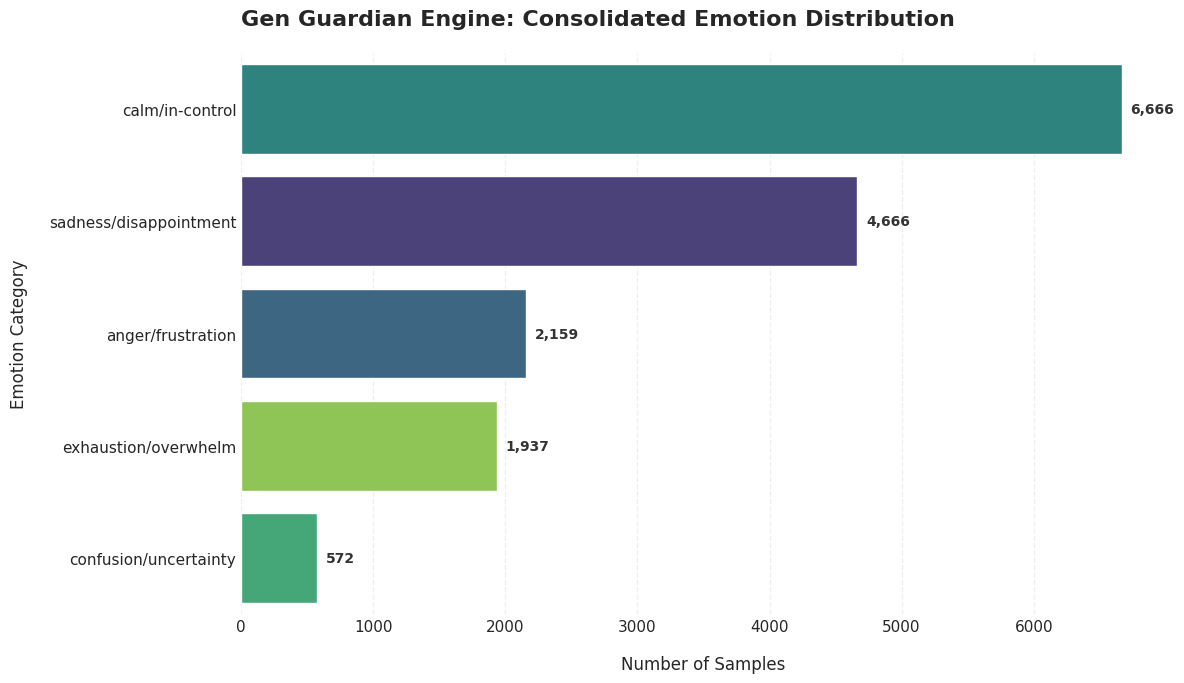

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Using a context manager for style keeps the rest of your notebook/environment clean
with sns.axes_style("white"):
    plt.figure(figsize=(12, 7))
    
    # Pre-calculating order to keep the plotting call readable
    category_order = df['consolidated_emotion'].value_counts().index
    
    ax = sns.countplot(
        data=df, 
        y='consolidated_emotion', 
        order=category_order,
        hue='consolidated_emotion', # Explicitly mapping hue avoids warnings
        palette='viridis',
        legend=False
    )

    # Title and Labels
    plt.title('Gen Guardian Engine: Consolidated Emotion Distribution', 
              fontsize=16, pad=20, fontweight='bold', loc='left')
    plt.xlabel('Number of Samples', fontsize=12, labelpad=15)
    plt.ylabel('Emotion Category', fontsize=12, labelpad=15)

    # Dynamic Label Placement
    max_width = df['consolidated_emotion'].value_counts().max()
    offset = max_width * 0.01  # Labels sit 1% of the max scale away from the bar
    
    for p in ax.patches:
        width = p.get_width()
        ax.text(
            width + offset, 
            p.get_y() + p.get_height() / 2, 
            f'{int(width):,}', # Added comma formatting for thousands
            ha='left', 
            va='center',
            fontsize=10,
            fontweight='600',
            color='#333333'
        )

    # Clean up spines and add a subtle vertical grid
    sns.despine(left=True, bottom=True)
    ax.xaxis.grid(True, linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [28]:
print(df.columns)

Index(['text', 'label', 'emotion_name', 'consolidated_emotion'], dtype='str')


In [29]:
from sklearn.model_selection import train_test_split

# Split data (Stratified to ensure balanced classes in train/test)
X = df['text']
y = df['consolidated_emotion']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

# --- BASELINE: Keyword Matching Heuristic ---
#  scores based on keyword density.
def keyword_baseline_predict(text):
    text_lower = text.lower()
    scores = {
        'anger/frustration': len(re.findall(r'angry|mad|furious|hate|annoyed|stupid|idiot', text_lower)),
        'exhaustion/overwhelm': len(re.findall(r'tired|exhausted|overwhelmed|scared|fear|panic|stress', text_lower)),
        'calm/in-control': len(re.findall(r'good|happy|love|great|wonderful|peaceful|calm|relaxed', text_lower)),
        'sadness/disappointment': len(re.findall(r'sad|cry|tears|disappointed|hopeless|lonely|miss', text_lower)),
        'confusion/uncertainty': len(re.findall(r'confused|dont know|uncertain|surprised|wonder|maybe|why', text_lower)),
    }
    
    max_score = max(scores.values())
    if max_score == 0:
        return 'calm/in-control'  # Default fallback
    
    # Return the category with the highest score
    return [k for k, v in scores.items() if v == max_score][0]

# Evaluate Baseline
baseline_preds = [keyword_baseline_predict(t) for t in X_test]
baseline_acc = accuracy_score(y_test, baseline_preds)
baseline_f1 = f1_score(y_test, baseline_preds, average='weighted')

print(f"\n📊 Baseline Results:")
print(f"Accuracy: {baseline_acc:.4f}")
print(f"Weighted F1-Score: {baseline_f1:.4f}")

Training set size: 12800
Test set size: 3200

📊 Baseline Results:
Accuracy: 0.4419
Weighted F1-Score: 0.3479


In [30]:
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# 1. SVM Model
print("Training Linear SVM...")
svm_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('svm', LinearSVC(random_state=42, max_iter=5000))
])
svm_pipeline.fit(X_train, y_train)
svm_preds = svm_pipeline.predict(X_test)

# 2. Random Forest Model
print("Training Random Forest...")
rf_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)
rf_preds = rf_pipeline.predict(X_test)

# Evaluate Models
print("MODEL COMPARISON RESULTS")


models = {
    "Baseline (Keywords)": (baseline_preds, baseline_acc, baseline_f1),
    "Linear SVM": (svm_preds, accuracy_score(y_test, svm_preds), f1_score(y_test, svm_preds, average='weighted')),
    "Random Forest": (rf_preds, accuracy_score(y_test, rf_preds), f1_score(y_test, rf_preds, average='weighted'))
}

results_df = pd.DataFrame([
    {"Model": name, "Accuracy": acc, "Weighted F1": f1}
    for name, (_, acc, f1) in models.items()
])

print(results_df.to_string(index=False))

Training Linear SVM...
Training Random Forest...
MODEL COMPARISON RESULTS
              Model  Accuracy  Weighted F1
Baseline (Keywords)  0.441875     0.347868
         Linear SVM  0.921875     0.921121
      Random Forest  0.907500     0.907410



🔍 Detailed Classification Report (SVM):
                        precision    recall  f1-score   support

     anger/frustration       0.90      0.86      0.88       432
       calm/in-control       0.94      0.97      0.95      1333
 confusion/uncertainty       0.77      0.71      0.74       115
  exhaustion/overwhelm       0.88      0.85      0.86       387
sadness/disappointment       0.94      0.94      0.94       933

              accuracy                           0.92      3200
             macro avg       0.89      0.87      0.88      3200
          weighted avg       0.92      0.92      0.92      3200



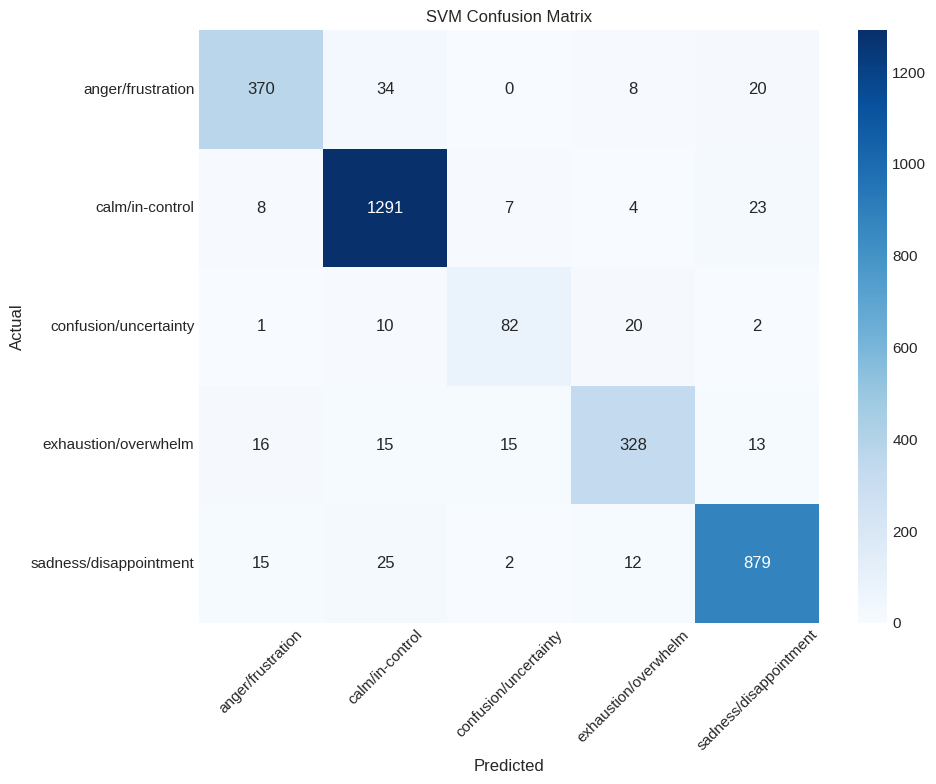


🚨 Found 250 misclassified samples.

Sample Errors (Actual vs Predicted):
Index: 4791
Actual: sadness/disappointment | Predicted: calm/in-control
Text: 'i am convinced that being encouraged to be obedient to the commandments of god when done with compassion and love by caring church family members do not leave us feeling abused trapped and hopeless but strengthened hopeful and cherished by both god and his church'

Index: 10315
Actual: anger/frustration | Predicted: exhaustion/overwhelm
Text: 'i feel like i m being tortured for government secrets i don t know anything'

Index: 7697
Actual: confusion/uncertainty | Predicted: exhaustion/overwhelm
Text: 'i am feeling a bit overwhelmed tired anxious etc'

Index: 4940
Actual: anger/frustration | Predicted: calm/in-control
Text: 'when i heard about the way a parent of a friend had mistreated him'

Index: 2713
Actual: confusion/uncertainty | Predicted: exhaustion/overwhelm
Text: 'i just feel overwhelmed thinking about it'



In [31]:
# Detailed Report for SVM
print("\n🔍 Detailed Classification Report (SVM):")
print(classification_report(y_test, svm_preds))

# Confusion Matrix for SVM
plt.figure(figsize=(10, 8))


# Get the sorted list of categories for consistent ordering
categories = sorted(df['consolidated_emotion'].unique())
cm_svm = confusion_matrix(y_test, svm_preds, labels=categories)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=categories,
            yticklabels=categories)
plt.title('SVM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- ERROR ANALYSIS FIX ---
# Create a DataFrame that aligns indices correctly
error_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': svm_preds,
    'Text': X_test  # This preserves the original index from the split
})

# Filter for errors
errors = error_df[error_df['Actual'] != error_df['Predicted']]

print(f"\n🚨 Found {len(errors)} misclassified samples.")
print("\nSample Errors (Actual vs Predicted):")

# Show first 5 errors
for idx, row in errors.head(5).iterrows():
    # Use .loc with the actual index 'idx'
    print(f"Index: {idx}")
    print(f"Actual: {row['Actual']} | Predicted: {row['Predicted']}")
    print(f"Text: '{row['Text']}'\n")

In [32]:
from sklearn.model_selection import GridSearchCV

# We use the same TF-IDF settings you already established in your draft
rf_tuning_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2), stop_words='english')),
    ('rf', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Tuning n_estimators (number of trees) to satisfy the 'in-depth' requirement
param_grid_rf = {
    'rf__n_estimators': [50, 100, 200],
    'rf__max_depth': [None, 20],
}

print("Running Grid Search for Random Forest...")
grid_rf = GridSearchCV(rf_tuning_pipeline, param_grid_rf, cv=5, scoring='accuracy')
grid_rf.fit(X_train, y_train)

# Update your results with the best tuned model
best_rf_model = grid_rf.best_estimator_
rf_tuned_preds = best_rf_model.predict(X_test)

# Update the results dictionary/dataframe
results_df.loc[results_df['Model'] == 'Random Forest', 'Accuracy'] = accuracy_score(y_test, rf_tuned_preds)
results_df.loc[results_df['Model'] == 'Random Forest', 'Weighted F1'] = f1_score(y_test, rf_tuned_preds, average='weighted')

print(f"✅ Best RF Parameters: {grid_rf.best_params_}")

Running Grid Search for Random Forest...
✅ Best RF Parameters: {'rf__max_depth': None, 'rf__n_estimators': 200}


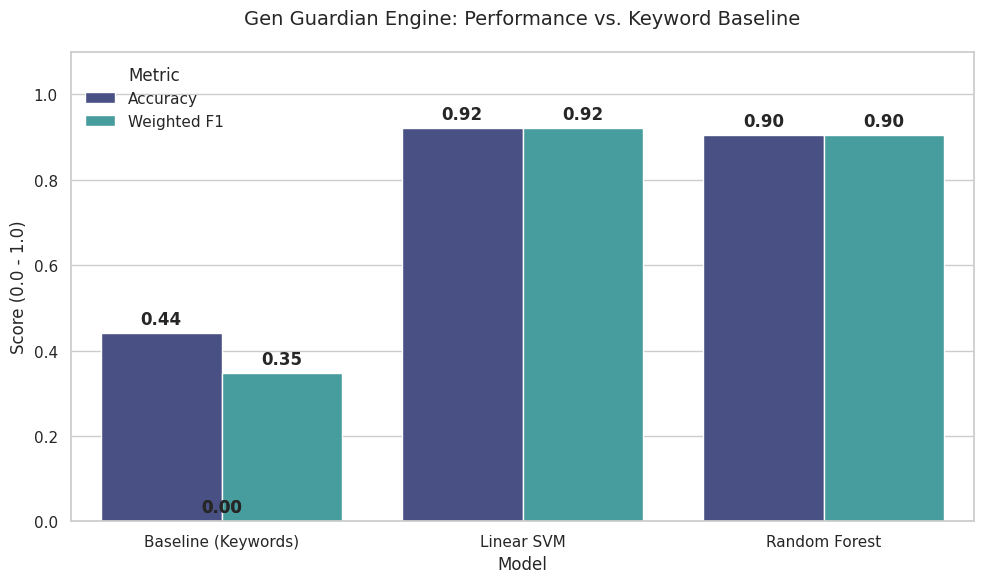

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Professional, colorblind-friendly palette
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Melt results for plotting
df_plot = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

# Generate the plot
ax = sns.barplot(data=df_plot, x='Model', y='Score', hue='Metric', palette='mako')

plt.title('Gen Guardian Engine: Performance vs. Keyword Baseline', fontsize=14, pad=20)
plt.ylabel('Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.1) 
plt.legend(title='Metric', loc='upper left')

# Add values on top of bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 10), 
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()